In [1]:
#file imports used
from PIL import Image
from bit_operators import BitFeederString, BitSaver
import os

In [2]:
#open a bmp and get its size
message="./dad.jpeg"
cover="./stego.bmp"
filesize = os.path.getsize(message)
x = Image.open(cover)
pic_size = x.size
num_of_pixels = pic_size[0]*pic_size[1]
available_bytes=(num_of_pixels*(3))/8
print("Filesize="+str(filesize)+"\nCapacity="+str(int(available_bytes)))
if filesize > available_bytes:
    print("This is not going to work.")

Filesize=107413
Capacity=921600


In [3]:
def length_in_bits(length):
    bits = bin(length)[2:]
    bits = '0'*(32-len(bits)) + bits
    return bits
def length_in_int(binary_input):
    return int(binary_input, 2)

bfeed = BitFeederString(message)
length = bfeed.get_length()
print(length)
in_bits = length_in_bits(length)
print(in_bits)
print(len(in_bits))
in_int = length_in_int(in_bits)
print(in_int)

859304
00000000000011010001110010101000
32
859304


In [4]:
#Makes sure we have an 8 bit byte from int
def byte_maker(color):
    return f'{color:08b}'
#returns an int from byte bin string
def int_maker(color):
    return int(color, 2)
#encodes however many bits specified
def encoder(cover,message,level=8):
    cover = cover[:level-1]+message+cover[level:]
    return cover

#PIXELS ENCODED
encoded_length = length_in_bits(length)
length_index = 0
for i in range(pic_size[0]):
    for j in range(pic_size[1]):
        color = x.getpixel((i,j))
        modified = []
        #print("OG"+str(color))
        for RGB in range(len(color)):
                input = color[RGB]
                #print(str(input))
                cover = byte_maker(input)
                if length_index < 32:
                    message = encoded_length[length_index]
                    length_index +=1
                    #print(message)
                else:
                    message = bfeed.get_bits(1)
                #print(cover)
                #message = bfeed.get_bits(1)
                #print(message)
                encoded = encoder(cover,message,level=4)
                #print(encoded)
                output = int(encoded, 2)
                #print(output)
                modified.append(output)
        x.putpixel( (i , j), (modified[0], modified[1], modified[2], 255))
        #print("MOD"+str(x.getpixel((i,j))))
        if bfeed.finished == True:
            break

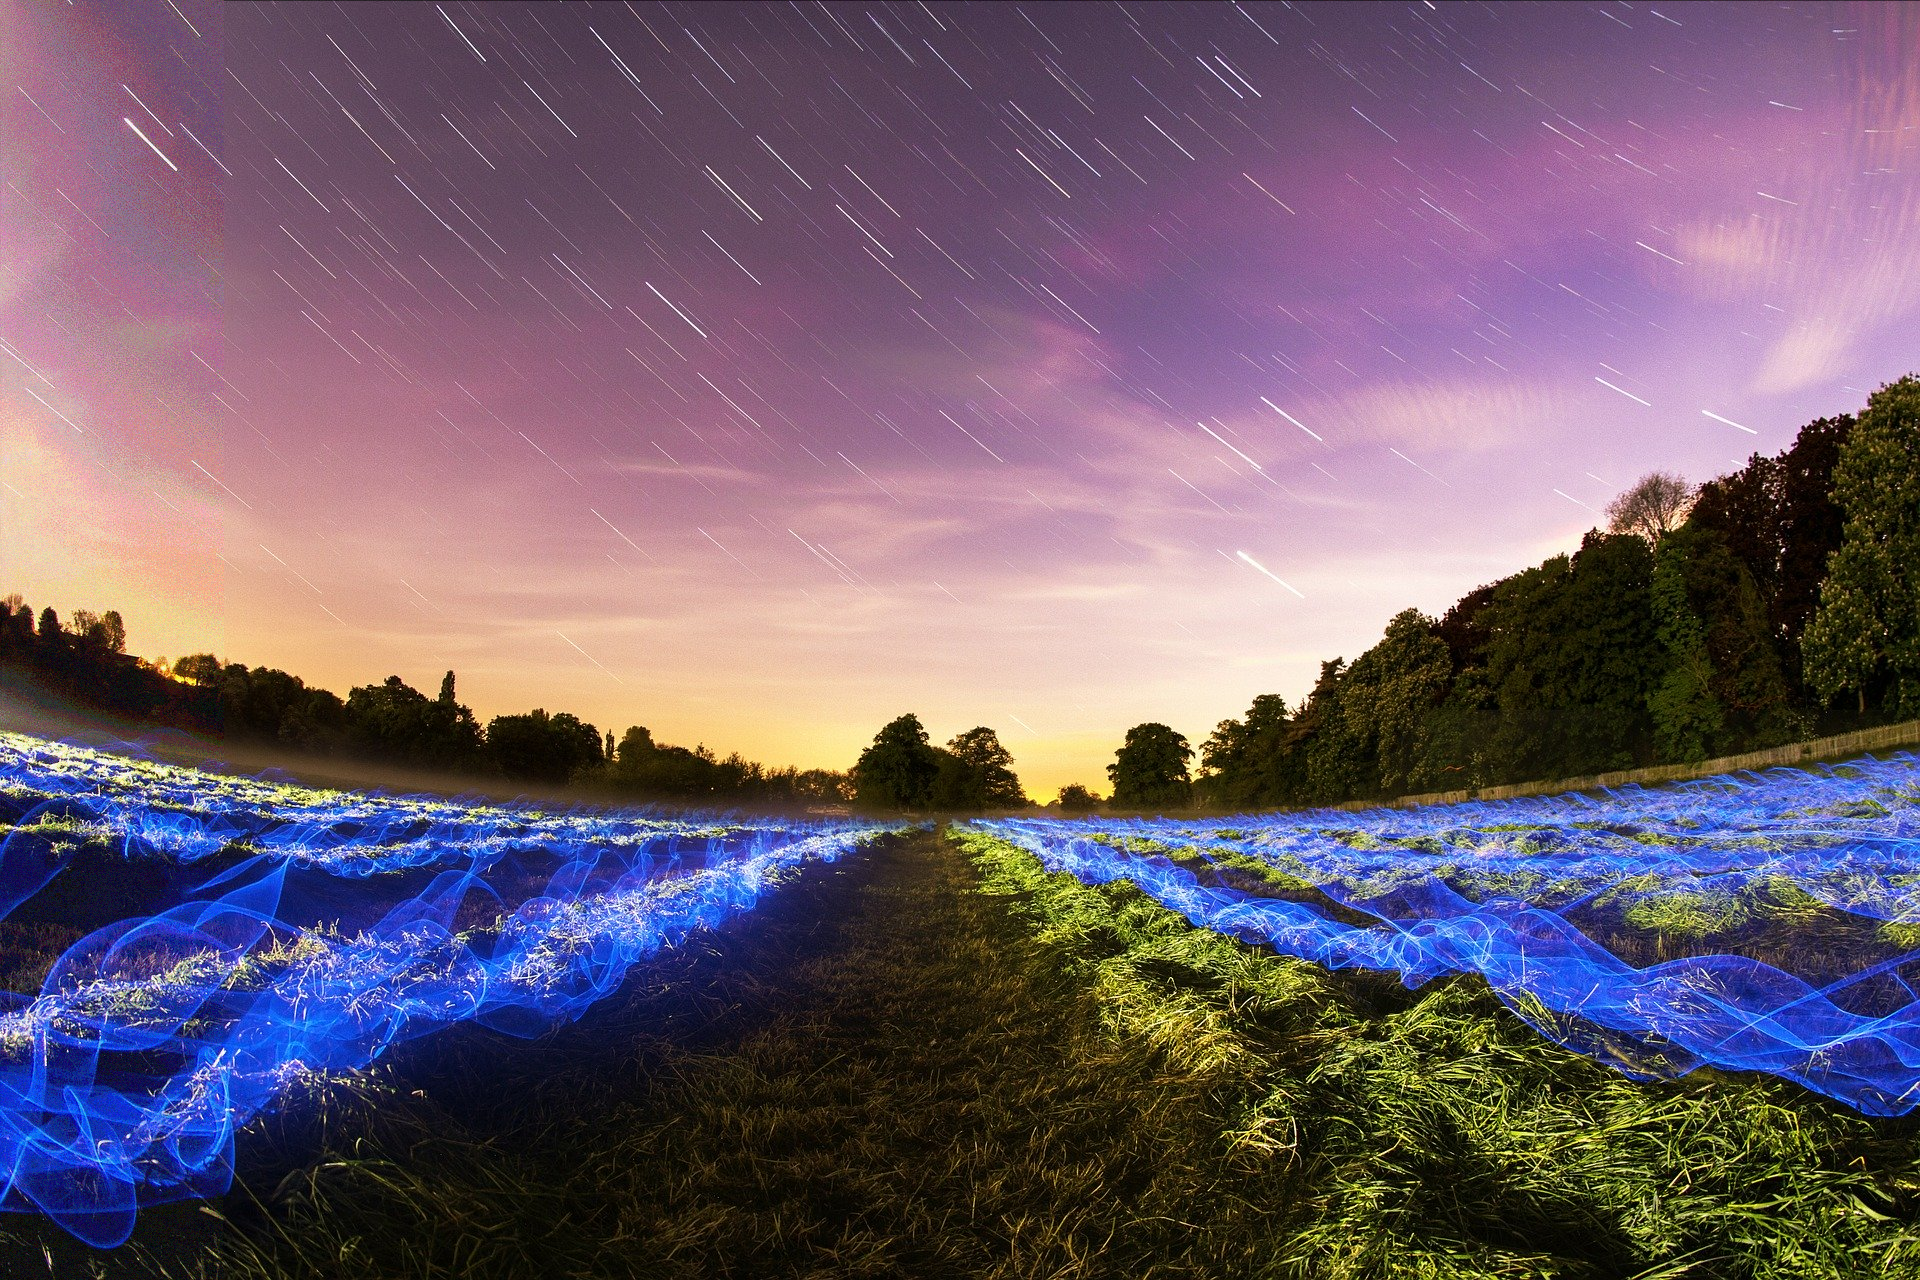

In [5]:
x

In [6]:
x.save("This_is_encoded.bmp", format="BMP")

In [8]:
x = Image.open("This_is_encoded.bmp")
bs = BitSaver(file_length=len(bfeed.bytes)*8)
print(len(bfeed.bytes)*8)

859304


In [9]:
def decoder(cover,level=8):
    return cover[level-1:level]

def get_length_from_file(x:Image,level=8):
    i = 0
    message_length_string = ''
    for j in range(11):
        if index < 32:
            color = x.getpixel((i,j))
            for RGB in range(len(color)):
                output=byte_maker(color[RGB])
                    #print(output)
                bit = decoder(output,level=level)
                message_length_string = message_length_string + bit
    print(message_length_string)
    message_length_string = message_length_string[:32]
    return(length_in_int(message_length_string)+32)



index = 0
finish = get_length_from_file(x,4)
print(finish)
for i in range(pic_size[0]):
    for j in range(pic_size[1]): 
        color = x.getpixel((i,j))
        for RGB in range(len(color)):
            if index < finish:
                output=byte_maker(color[RGB])
                #print(output)
                bit = decoder(output,level=4)
                if index < 32:
                    index+=1
                else:
                #print(bit)
                    bs.add_bits(bit)
                    index += 1
                #print(str(index)+ " " + str(bfeed.get_length()))
          

110110110110001001110110001001110
3680663111


AttributeError: 'str' object has no attribute 'append'

In [10]:
bs.save_file("output.jpg")